# Window functions: time and frequency-domain examples

Windowing multiplies a finite segment of a signal by a sequence $w[n]$. The window shape determines the trade-off between **main-lobe width** (ability to resolve nearby sinusoidal frequencies) and **side-lobe level** (spectral leakage from strong components to weaker ones).

This example compares three length-$M$ windows: **sine**, **Hann**, and **rectangular**. Each window is shown in the time domain and through its discrete-time Fourier transform (DTFT), sampled densely using a zero-padded FFT. This is a demonstration, not an exercise.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import windows

# All windows have the same length, and all spectra use the same FFT grid.
M = 64
n_fft = 16384   # Zero-padding samples the window spectrum more densely; it adds no resolution.
n = np.arange(M)
frequency = np.fft.rfftfreq(n_fft, d=1.0)  # Cycles/sample (0 to the Nyquist frequency 0.5).

# Periodic conventions are useful for windowed DFT/STFT analysis.
# sine: sin(pi*(n+1/2)/M), zero at half-sample positions outside the frame.
# Hann: scipy.signal.windows.hann(..., sym=False), periodic Hann.
# Rectangular: all ones, equivalent to taking a finite segment without tapering.
window_dict = {
    'Sine': np.sin(np.pi * (n + 0.5) / M),
    'Hann': windows.hann(M, sym=False),
    'Rectangular': np.ones(M),
}


def window_spectrum_db(window, fft_size=n_fft, floor_db=-120.0):
    """Return one-sided magnitude spectrum in dB, referenced to its DC peak (0 dB)."""
    # Divide by sum(window) for unit DC gain so window shapes can be compared fairly.
    normalized = window / np.sum(window)
    magnitude = np.abs(np.fft.rfft(normalized, n=fft_size))
    # Clip only for display, to avoid log10(0) and values below the plotting floor.
    return 20 * np.log10(np.maximum(magnitude, 10 ** (floor_db / 20)))

print(f'Window length: {M} samples; FFT length: {n_fft} samples')

Window length: 64 samples; FFT length: 16384 samples


## 1. Individual window shapes and spectra

The **time-domain plot** shows how a window weights samples near the ends of a frame. The **frequency-domain plot** shows the response of the window itself, with its maximum normalized to 0 dB. A narrower main lobe generally makes close frequencies easier to distinguish, whereas lower side lobes reduce leakage into distant frequencies.

The horizontal spectral axis is in **DFT-bin spacings** ($fM$): 1 unit corresponds to $1/M$ cycles/sample. This makes the window shapes easy to compare independently of sampling rate. It is not an audio frequency axis in Hz.

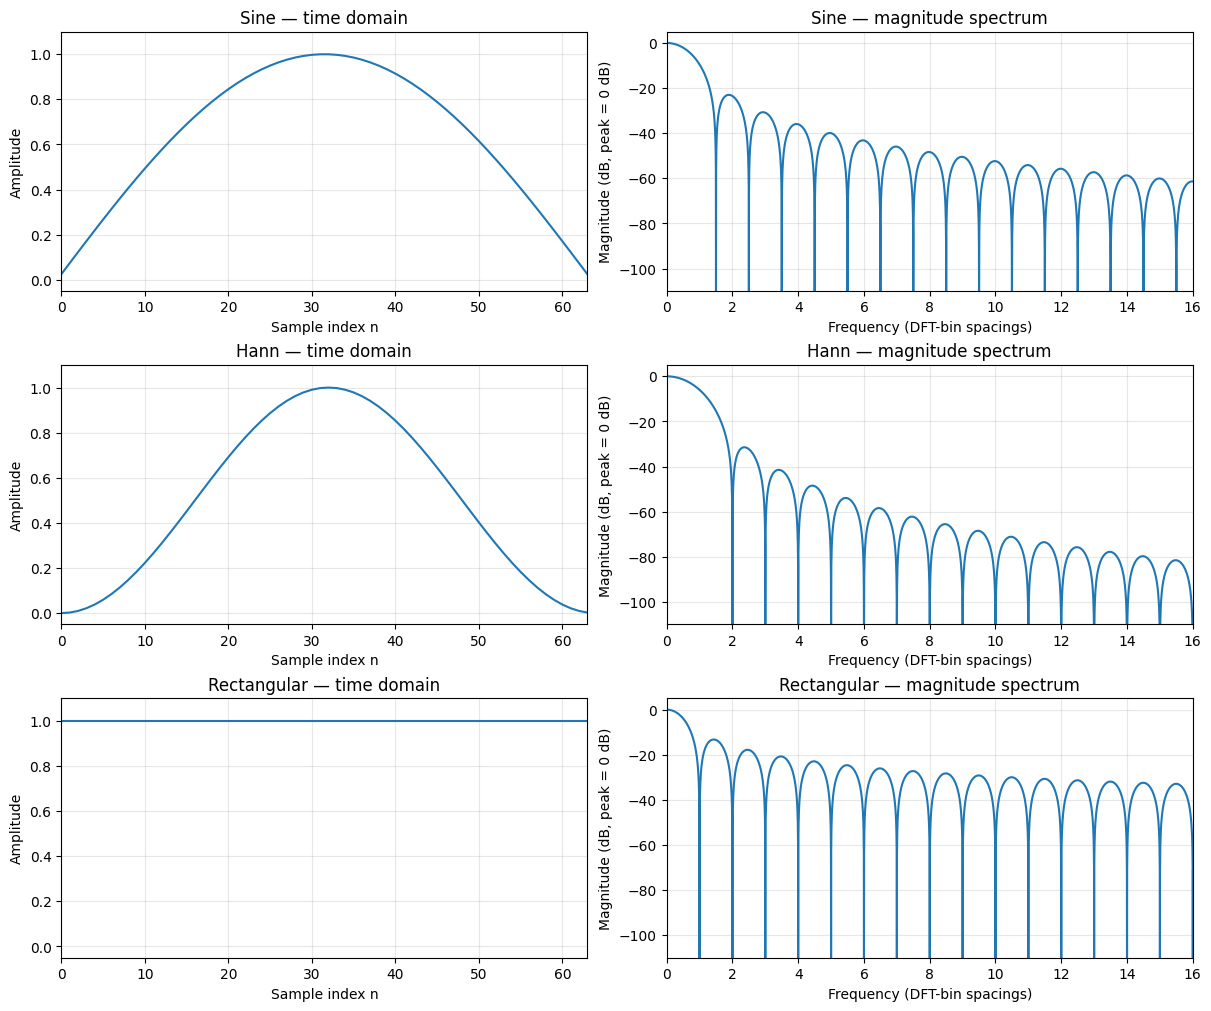

In [2]:
# Same plotting scales for all three windows, so the differences are visible.
fig, axes = plt.subplots(3, 2, figsize=(12, 10), constrained_layout=True)
for row, (name, win) in enumerate(window_dict.items()):
    spectrum = window_spectrum_db(win)
    axes[row, 0].plot(n, win)
    axes[row, 0].set(title=f'{name} — time domain', xlabel='Sample index n', ylabel='Amplitude',
                     xlim=(0, M-1), ylim=(-0.05, 1.1))
    axes[row, 0].grid(alpha=0.3)

    axes[row, 1].plot(frequency * M, spectrum)
    axes[row, 1].set(title=f'{name} — magnitude spectrum', xlabel='Frequency (DFT-bin spacings)',
                     ylabel='Magnitude (dB, peak = 0 dB)', xlim=(0, 16), ylim=(-110, 5))
    axes[row, 1].grid(alpha=0.3)
plt.show()

## 2. Direct comparison of spectral leakage

The **rectangular window** has the narrowest central lobe of these three examples, but its first side lobe is relatively high (about −13 dB). The **Hann window** has a wider main lobe with much lower side lobes (the first is about −31 dB). The **sine window** provides an intermediate trade-off (first side lobe approximately −23 dB).

A low side-lobe level is important when a weak sinusoid is close in frequency to a strong one. **Zero-padding does not improve the underlying frequency resolution**: it only produces a smoother-looking plot by evaluating the same transform on a denser frequency grid.

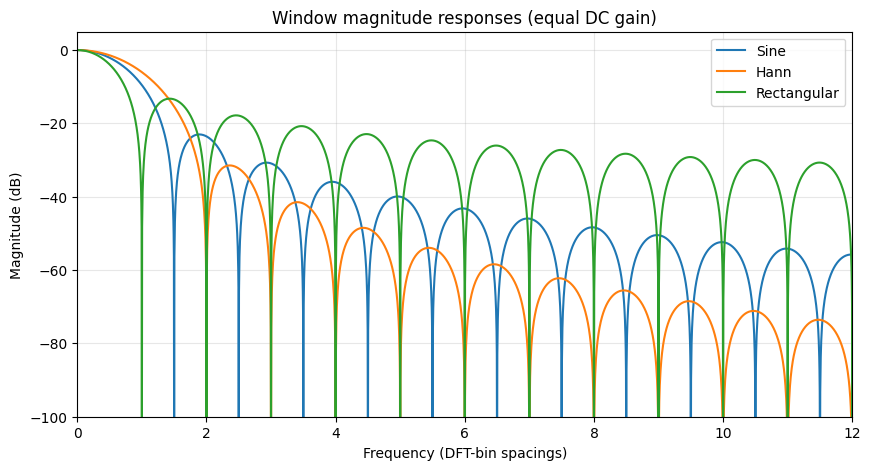

In [3]:
plt.figure(figsize=(10, 5))
for name, win in window_dict.items():
    plt.plot(frequency * M, window_spectrum_db(win), label=name)
plt.title('Window magnitude responses (equal DC gain)')
plt.xlabel('Frequency (DFT-bin spacings)')
plt.ylabel('Magnitude (dB)')
plt.xlim(0, 12)
plt.ylim(-100, 5)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 3. Effect on the spectrum of a sinusoid

A sinusoid whose frequency lies **between DFT bin centers** spreads its energy across many bins when we analyze a finite segment. Multiplying the signal by a tapering window reduces far-away leakage at the cost of broadening the main lobe. The following example uses a sinusoid at **5.5 cycles per window**; its energy is not centered on an integer DFT bin.

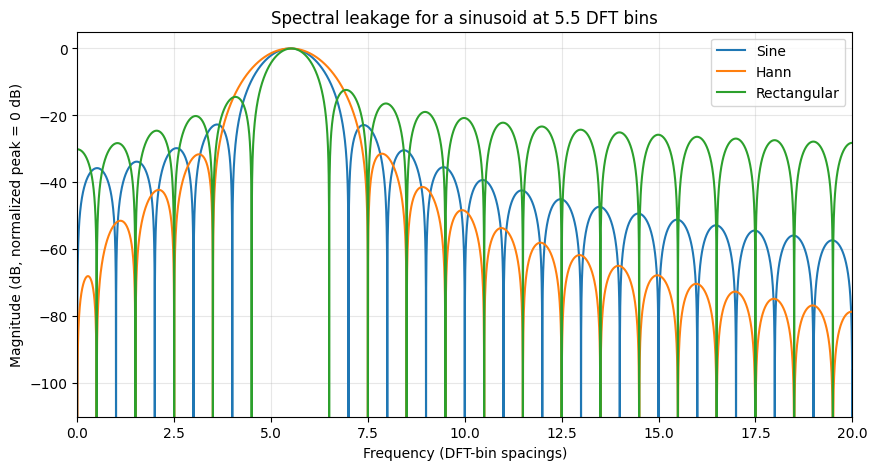

In [4]:
# A sinusoid at a half-bin offset emphasizes leakage differences.
cycles_per_window = 5.5
x = np.cos(2 * np.pi * cycles_per_window * n / M)

plt.figure(figsize=(10, 5))
for name, win in window_dict.items():
    # Compare magnitude relative to the largest peak of each windowed sinusoid.
    magnitude = np.abs(np.fft.rfft(x * win, n=n_fft))
    magnitude /= np.max(magnitude)
    db = 20 * np.log10(np.maximum(magnitude, 1e-6))
    plt.plot(frequency * M, db, label=name)
plt.title('Spectral leakage for a sinusoid at 5.5 DFT bins')
plt.xlabel('Frequency (DFT-bin spacings)')
plt.ylabel('Magnitude (dB, normalized peak = 0 dB)')
plt.xlim(0, 20)
plt.ylim(-110, 5)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## What to remember

- A window weights the samples of a finite-time frame and changes its spectral leakage pattern.
- **Rectangular**: narrowest main lobe here, but relatively strong side lobes.
- **Hann**: wider main lobe, lower side lobes; widely used in spectral analysis.
- **Sine**: intermediate leakage trade-off and also relevant to overlapping transform systems (such as the MDCT).
- Normalize spectra consistently before comparing them. Zero-padding makes the curves smoother but does **not** add resolving power.
- The examples use the **periodic Hann** convention; a symmetric Hann has slightly different endpoints and is commonly used for FIR-filter design.